# Sensitivity-calculator prototype

This notebook estimates either **S/N for an integration time** or **integration time for a requested S/N**, for any combination of instruments and imaging filters:

| Instrument | Filters | Throughputs | Reference limits |
|---|---|---|---|
| JWST/NIRCam | all 29 imaging filters | STScI detector-averaged total-system curves, v7.0 | STScI ETC v5.0: S/N = 10 in 10 ks |
| HST/WFC3/UVIS | F225W, F336W, F438W, F606W, F814W | STScI total-system curves (UVIS1, Oct 2020 calibration) | WFC3 Instrument Handbook Table 6.10: S/N = 10 in 1 hr |
| HST/WFC3/IR | F110W, F160W | STScI total-system curves (Oct 2020 calibration) | WFC3 Instrument Handbook Table 7.10: S/N = 10 in 1 hr |

Only WFC3 filters with a published limiting magnitude are offered. Select several instruments and filters below and the results are reported for each of them.

## Model

Each filter has a published reference: $S/N_0$ at time $t_0$ for flux density $F_{\nu,0}$ ($S/N_0 = 10$ for every instrument; $t_0 = 10^4$ s for NIRCam and $3600$ s for WFC3). The prototype scales it as

$$S/N = (S/N)_0\,\frac{F_\nu}{F_{\nu,0}}\sqrt{\frac{t}{t_0}},$$

$$t = t_0\left(\frac{S/N}{(S/N)_0}\right)^2\left(\frac{F_{\nu,0}}{F_\nu}\right)^2.$$

For a blackbody, stellar-population template, or uploaded spectrum normalized by an AB magnitude in one filter of *any* instrument, photon-counting synthetic photometry transfers that normalization to every observing filter.

In [1]:
from pathlib import Path
import sys

repo_root = Path.cwd() if (Path.cwd() / "sensitivity_calculator").exists() else Path.cwd().parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
import pandas as pd
from IPython.display import Markdown, display, clear_output

from sensitivity_calculator import (BlackbodySED, FluxSystem, SensitivityCalculator, TabulatedSED,
                                    load_fsps_library, load_instruments, sensitivity_table)
from sensitivity_calculator.plotting import PLOT_STYLE, active_range, plot_sed_with_bandpasses, plot_throughputs
from sensitivity_calculator.seds import SPECTRUM_FILE_EXTENSIONS, flux_system_label, read_spectrum_file
from sensitivity_calculator.photometry import ab_magnitude_to_njy, njy_to_ab_magnitude

instruments = load_instruments()  # {"JWST/NIRCam": ..., "HST/WFC3/UVIS": ..., "HST/WFC3/IR": ...}
INSTRUMENT_COLORS = {"JWST/NIRCam": "tab:red", "HST/WFC3/UVIS": "tab:purple", "HST/WFC3/IR": "tab:orange"}
for label, inst in instruments.items():
    print(f"Loaded {label}: {len(inst.filters)} imaging filters ({', '.join(inst.filters)})")

Loaded JWST/NIRCam: 29 imaging filters (F070W, F090W, F115W, F140M, F150W, F162M, F164N, F150W2, F182M, F187N, F200W, F210M, F212N, F250M, F277W, F300M, F322W2, F323N, F335M, F356W, F360M, F405N, F410M, F430M, F444W, F460M, F466N, F470N, F480M)
Loaded HST/WFC3/UVIS: 5 imaging filters (F225W, F336W, F438W, F606W, F814W)
Loaded HST/WFC3/IR: 2 imaging filters (F110W, F160W)


## Inspect the reference data

In [2]:
reference_table = pd.DataFrame([
    {
        "instrument": label,
        "filter": name,
        "pivot_um": bp.pivot_um,
        "published_pivot_um": bp.pivot_um_published,
        "ref_snr": inst.sensitivities[name].snr,
        "ref_time_s": inst.sensitivities[name].exposure_s,
        "ref_flux_nJy": inst.sensitivities[name].flux_njy,
        "ref_AB": njy_to_ab_magnitude(inst.sensitivities[name].flux_njy),
    }
    for label, inst in instruments.items()
    for name, bp in inst.bandpasses.items()
])
display(reference_table.style.hide(axis="index").format({
    "pivot_um": "{:.4f}", "published_pivot_um": "{:.4f}", "ref_snr": "{:g}", "ref_time_s": "{:g}",
    "ref_flux_nJy": "{:.1f}", "ref_AB": "{:.2f}",
}))

instrument,filter,pivot_um,published_pivot_um,ref_snr,ref_time_s,ref_flux_nJy,ref_AB
JWST/NIRCam,F070W,0.7047,0.7050,10,10000,14.2,28.52
JWST/NIRCam,F090W,0.9024,0.9020,10,10000,11.9,28.71
JWST/NIRCam,F115W,1.1541,1.1540,10,10000,11.1,28.79
JWST/NIRCam,F140M,1.4053,1.4050,10,10000,15.1,28.45
JWST/NIRCam,F150W,1.5009,1.5010,10,10000,9.1,29.00
JWST/NIRCam,F162M,1.6272,1.6270,10,10000,14.7,28.48
JWST/NIRCam,F164N,1.6445,1.6450,10,10000,90.4,26.51
JWST/NIRCam,F150W2,1.6718,1.6720,10,10000,4.5,29.77
JWST/NIRCam,F182M,1.8452,1.8450,10,10000,11.8,28.72
JWST/NIRCam,F187N,1.8741,1.8740,10,10000,80.9,26.63


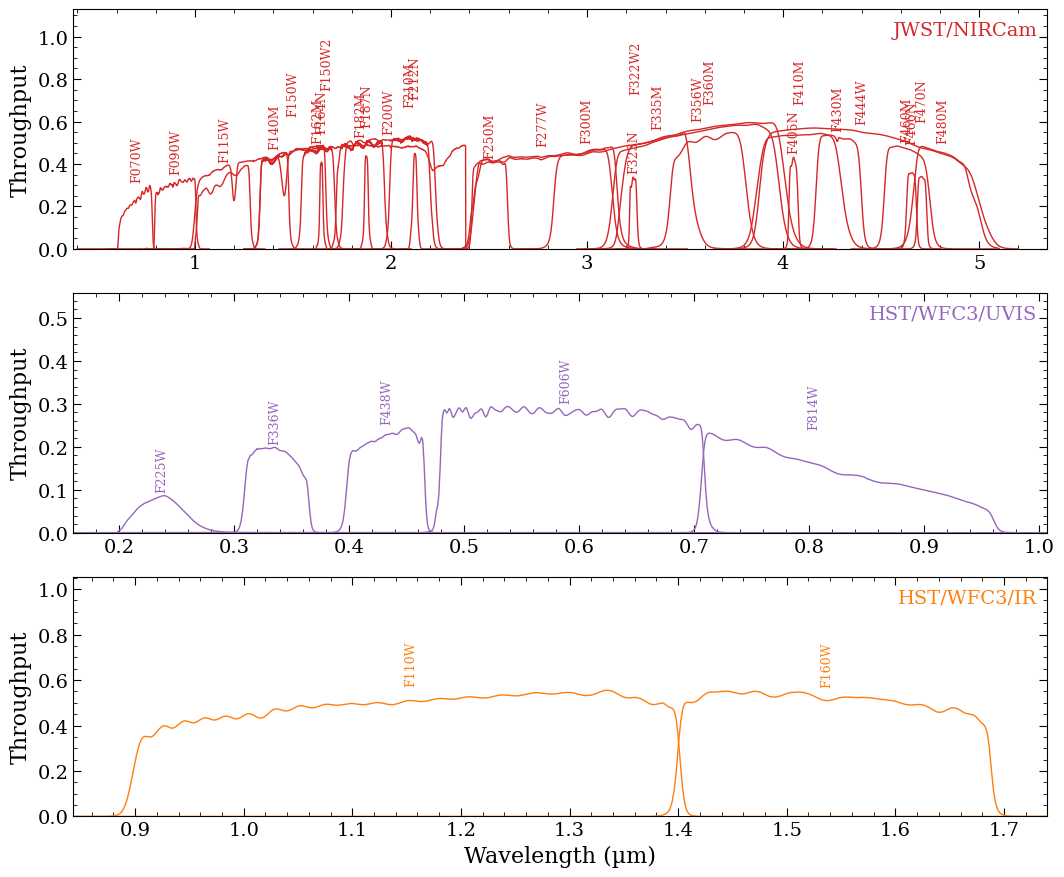

In [3]:
plot_throughputs(instruments, colors=INSTRUMENT_COLORS)
plt.show()

## Interactive calculator

**Instruments and filters.** Tick one or more instruments and select one or more filters in each list (Ctrl/Cmd-click toggles a filter, Shift-click selects a range). The results table has one row per selected filter, ordered by pivot wavelength.

Choose **Direct AB magnitude** when the source magnitude is known; it is then applied in *every* selected filter (a source flat in $F_\nu$). Choose **Blackbody**, **Stellar population template**, or **Uploaded spectrum** to transfer an AB normalization from one filter of any instrument (e.g. normalize in NIRCam F090W and observe in WFC3 F606W and F160W). For these sources the result includes a plot of the normalized spectrum, with the normalization filter (blue) and the observing filters (colored by instrument) shaded and their band-averaged fluxes marked.

**Stellar population templates** come from `fsps_template_library/` (FSPS simple stellar populations: 16 ages from 0.1 to 14 Gyr, [Z/H] = −0.5, 0, +0.2, no dust or nebular emission). The rest-frame templates are redshifted to the chosen $z$ by stretching the wavelength axis. Other libraries can be added by giving them a `manifest.json` (see `sensitivity_calculator/templates.py`).

**Uploaded spectra** may be any plain-text table (`.dat`, `.txt`, `.flm`, `.csv`, `.tsv`, `.ascii`, `.spec`, IPAC `.tbl`, ...; whitespace, tab, comma, or semicolon delimited; header rows and `#`/`%`/`!` comments are skipped) or a FITS spectrum. **Column 1 must be the wavelength (spectral axis) and column 2 the flux**; any further columns (errors, sky, ...) are ignored. The spectrum is plotted as soon as it is uploaded. Only the spectral *shape* is used, so the overall scale and constant unit factors (Jy vs mJy, per Å vs per µm) do not matter. You must still specify the **spectral-axis unit** and the **flux convention**, because converting to $F_\nu$ introduces wavelength-dependent factors: $F_\nu \propto \lambda^2 F_\lambda$, $\propto \lambda\,(\lambda F_\lambda)$, $\propto \lambda N_\lambda$ for photon flux, and $\propto 10^{-0.4\,m_{\rm AB}}$. The spectrum must cover the normalization filter and each observing filter; it is never extrapolated. A filter it does not cover is flagged in the results table and the others are still computed. Note that the WFC3 UV filters (F225W, F336W, F438W) have red leaks: their throughput extends, at a low level, to about 1 µm, and the spectrum must cover that too. Vega-magnitude spectra are not yet supported.

In [3]:
style = {"description_width": "110px"}

# --- Instrument and filter selection -----------------------------------------
DEFAULT_FILTERS = {"JWST/NIRCam": ("F200W", "F444W"), "HST/WFC3/UVIS": ("F606W",), "HST/WFC3/IR": ("F160W",)}
instrument_checks, filter_selectors, instrument_columns = {}, {}, []
for label, inst in instruments.items():
    check = widgets.Checkbox(value=True, description=label, indent=False, layout=widgets.Layout(width="190px"))
    chooser = widgets.SelectMultiple(
        options=[(f"{name}  ({bp.pivot_um:.3f} µm)", name) for name, bp in inst.bandpasses.items()],
        value=[f for f in DEFAULT_FILTERS.get(label, ()) if f in inst.filters],
        rows=min(10, len(inst.filters)), layout=widgets.Layout(width="190px"),
    )
    check.observe(lambda change, chooser=chooser: setattr(chooser, "disabled", not change["new"]), names="value")
    instrument_checks[label], filter_selectors[label] = check, chooser
    instrument_columns.append(widgets.VBox([check, chooser]))
selection_hint = widgets.HTML("<small>Tick instruments; Ctrl/Cmd-click to select several filters, Shift-click for a range.</small>")

def selected_filters():
    # (instrument label, filter) pairs of the ticked instruments, ordered by pivot wavelength.
    pairs = [(label, name) for label, check in instrument_checks.items() if check.value
             for name in filter_selectors[label].value]
    return sorted(pairs, key=lambda p: instruments[p[0]].bandpasses[p[1]].pivot_um)

# Model-spectrum libraries (any directory with a manifest.json works; see sensitivity_calculator/templates.py).
template_libraries = {}
try:
    template_libraries["FSPS simple stellar populations"] = load_fsps_library()
except FileNotFoundError as exc:
    print(f"FSPS template library not loaded: {exc}")

SOURCES = {
    "Blackbody normalized in another filter": "blackbody",
    "Stellar population template normalized in another filter": "template",
    "Uploaded spectrum normalized in another filter": "uploaded",
    "Direct AB magnitude": "direct",
}
if not template_libraries:
    SOURCES = {k: v for k, v in SOURCES.items() if v != "template"}
source_mode = widgets.Dropdown(options=list(SOURCES.items()), value="blackbody", description="Source:", style=style, layout=widgets.Layout(width="480px"))
normalization_filter = widgets.Dropdown(
    options=[(f"{label} {name}", (label, name)) for label, inst in instruments.items() for name in inst.filters],
    value=("JWST/NIRCam", "F090W"), description="Normalize in:", style=style, layout=widgets.Layout(width="300px"),
)
ab_magnitude = widgets.FloatText(value=25.0, description="AB magnitude:", style=style)
temperature = widgets.FloatText(value=10000.0, description="T (K):", style=style)

# --- Template-library controls: one dropdown per manifest parameter -----------
PARAMETER_LABELS = {"age_gyr": "Age (Gyr):", "logzsol": "[Z/H]:", "teff": "T_eff (K):", "logg": "log g:"}

def parameter_option(name, value):
    if name == "logzsol":
        return ("0 (solar)" if value == 0 else f"{value:+g}", value)
    return (f"{value:g}" if isinstance(value, (int, float)) else str(value), value)

template_library = widgets.Dropdown(options=list(template_libraries), description="Library:", style=style, layout=widgets.Layout(width="480px"))
template_parameters = widgets.HBox()
redshift = widgets.BoundedFloatText(value=0.0, min=0.0, max=30.0, step=0.1, description="Redshift z:", style=style)

def build_template_controls(*_):
    if not template_libraries:
        return
    lib = template_libraries[template_library.value]
    controls = []
    for name in lib.parameter_names:
        values = lib.parameter_values(name)
        default = 0.0 if name == "logzsol" and 0.0 in values else values[len(values) // 2]
        dd = widgets.Dropdown(options=[parameter_option(name, v) for v in values], value=default,
                              description=PARAMETER_LABELS.get(name, f"{name}:"), style=style)
        dd.parameter_name = name
        controls.append(dd)
    template_parameters.children = controls

def selected_template_sed():
    lib = template_libraries[template_library.value]
    params = {dd.parameter_name: dd.value for dd in template_parameters.children}
    return lib.sed(redshift=redshift.value, **params)

template_library.observe(build_template_controls, names="value")
build_template_controls()
template_row = widgets.VBox([template_library, template_parameters, redshift])

# --- Uploaded-spectrum controls ----------------------------------------------
# accept="" lets any file be chosen; the reader identifies text tables and FITS from content.
spectrum_file = widgets.FileUpload(accept="", multiple=False, description="Upload spectrum")
spectrum_hint = widgets.HTML(
    "(columns 1 and 2 must be <b>wavelength</b> and <b>flux</b>; extra columns are ignored)<br>"
    f"<small>Text tables ({', '.join(e for e in SPECTRUM_FILE_EXTENSIONS if 'fit' not in e)}, ...) or FITS</small>"
)
spectrum_preview = widgets.Output()
wavelength_unit = widgets.Dropdown(options=[("Å", "Angstrom"), ("nm", "nm"), ("µm", "um"), ("Hz", "Hz"), ("GHz", "GHz"), ("keV", "keV")], value="Angstrom", description="Axis unit:", style=style)
flux_system = widgets.Dropdown(options=[(flux_system_label(s), s.value) for s in FluxSystem if s is not FluxSystem.VEGA_MAG], value=FluxSystem.F_LAMBDA.value, description="Flux column:", style=style, layout=widgets.Layout(width="420px"))
spectrum_row = widgets.VBox([
    widgets.HBox([spectrum_file, spectrum_hint]),
    widgets.HBox([wavelength_unit, flux_system]),
    spectrum_preview,
])

exposure = widgets.FloatText(value=3600.0, description="Exposure (s):", style=style)
target_snr = widgets.FloatText(value=10.0, description="Target S/N:", style=style)
run_button = widgets.Button(description="Calculate", button_style="primary", icon="calculator")
output = widgets.Output()

# Wavelengths where any filter of each instrument transmits >1% of its peak.
INSTRUMENT_RANGES_UM = {
    label: (min(active_range(bp)[0] for bp in inst.bandpasses.values()),
            max(active_range(bp)[1] for bp in inst.bandpasses.values()))
    for label, inst in instruments.items()
}

def plot_range_um(labels, extra_bandpass=None):
    # Span of the chosen instruments (and the normalization band), padded but kept positive.
    spans = [INSTRUMENT_RANGES_UM[label] for label in labels]
    if extra_bandpass is not None:
        spans.append(active_range(extra_bandpass))
    lo, hi = min(s[0] for s in spans), max(s[1] for s in spans)
    pad = 0.05 * (hi - lo)
    return lo - min(pad, 0.2 * lo), hi + pad

def update_visibility(*_):
    mode = source_mode.value
    normalization_filter.layout.display = "none" if mode == "direct" else ""
    temperature.layout.display = "" if mode == "blackbody" else "none"
    template_row.layout.display = "" if mode == "template" else "none"
    spectrum_row.layout.display = "" if mode == "uploaded" else "none"

def load_uploaded_spectrum():
    if not spectrum_file.value:
        raise ValueError("Upload a spectrum file first")
    item = spectrum_file.value[0]  # ipywidgets 8: tuple of dicts
    return TabulatedSED.from_file(item["content"], wavelength_unit.value, flux_system.value, name=item["name"])

def show_spectrum_preview(*_):
    # Plot the uploaded spectrum (column 1 vs column 2) as soon as it is chosen.
    with spectrum_preview:
        clear_output(wait=True)
        if not spectrum_file.value:
            return
        item = spectrum_file.value[0]
        try:
            spec = read_spectrum_file(bytes(item["content"]), name=item["name"])
        except Exception as exc:
            display(Markdown(f"**Could not read `{item['name']}`:** `{exc}`"))
            return
        good = np.isfinite(spec.wavelength) & np.isfinite(spec.flux)
        x, y = spec.wavelength[good], spec.flux[good]
        unit = u.Unit(wavelength_unit.value)
        try:
            wave_um = (x * unit).to_value(u.um, equivalencies=u.spectral())
        except Exception as exc:
            display(Markdown(f"**Cannot convert spectral axis:** `{exc}`"))
            return
        order = np.argsort(wave_um)
        wave_um, y = wave_um[order], y[order]
        shown = [label for label, check in instrument_checks.items() if check.value] or list(instruments)

        cols = f"{spec.n_columns} columns" + (f" ({', '.join(spec.column_names)})" if spec.column_names else "")
        coverage = ", ".join(f"{label} {INSTRUMENT_RANGES_UM[label][0]:.2f}–{INSTRUMENT_RANGES_UM[label][1]:.2f} µm" for label in shown)
        notes = [
            f"**`{spec.name}`** — {spec.format}, {good.sum()} valid rows, {cols}; "
            f"using column 1 as wavelength [{wavelength_unit.label}] and column 2 as flux.",
            f"Coverage {wave_um[0]:.4g}–{wave_um[-1]:.4g} µm (filters: {coverage}).",
        ]
        if spec.n_columns > 2:
            notes.append(f"{spec.n_columns - 2} extra column(s) ignored.")
        if (~good).sum():
            notes.append(f"{(~good).sum()} non-finite row(s) dropped.")
        missed = [label for label in shown
                  if wave_um[-1] < INSTRUMENT_RANGES_UM[label][0] or wave_um[0] > INSTRUMENT_RANGES_UM[label][1]]
        if missed:
            notes.append(f"**No overlap with {', '.join(missed)}** — check the axis unit.")
        display(Markdown("  \n".join(notes)))

        with plt.rc_context(PLOT_STYLE):
            fig, ax = plt.subplots(figsize=(9, 3.6))
            ax.plot(wave_um, y, lw=1, color="k")
            for j, label in enumerate(shown):
                lo, hi = INSTRUMENT_RANGES_UM[label]
                color = INSTRUMENT_COLORS.get(label, "tab:blue")
                ax.axvspan(lo, hi, color=color, alpha=0.08, lw=0)
                ax.text(0.5 * (max(lo, wave_um[0]) + min(hi, wave_um[-1])), 0.95 - 0.09 * j, label,
                        transform=ax.get_xaxis_transform(), ha="center", va="top", color=color, fontsize=12)
            ax.text(0.99, 0.05, spec.name, transform=ax.transAxes, ha="right", va="bottom", fontsize=12)
            ax.set_xlim(wave_um[0], wave_um[-1])
            ax.set_xlabel("Wavelength (µm)")
            ax.set_ylabel(flux_system_label(flux_system.value).split(" (")[0] + " (as uploaded)")
            if flux_system.value == FluxSystem.AB_MAG.value:
                ax.invert_yaxis()
            fig.tight_layout()
            plt.show()

def results_frame(rows):
    t, s = exposure.value, target_snr.value
    frame = pd.DataFrame([{
        "Instrument": r["instrument"],
        "Filter": r["filter"],
        "Pivot (µm)": r["pivot_um"],
        "Fν (nJy)": r["flux_njy"],
        "AB mag": r["ab_mag"],
        f"S/N in {t:g} s": r["snr"],
        f"t for S/N={s:g} (s)": r["exposure_time_s"],
        "t (hr)": r["exposure_time_s"] / 3600,
        "Reference": f"S/N {r['reference'].snr:g} for {r['reference'].flux_njy:.3g} nJy in {r['reference'].exposure_s:g} s",
        "Problem": r["error"] or "",
    } for r in rows])
    if not frame["Problem"].any():
        frame = frame.drop(columns="Problem")
    return frame.style.hide(axis="index").format(na_rep="—", formatter={
        "Pivot (µm)": "{:.3f}", "Fν (nJy)": "{:.4g}", "AB mag": "{:.3f}",
        f"S/N in {t:g} s": "{:.3g}", f"t for S/N={s:g} (s)": "{:.4g}", "t (hr)": "{:.3g}",
    })

def run_calculation(_=None):
    with output:
        clear_output()
        try:
            selections = selected_filters()
            if not selections:
                raise ValueError("Select at least one observing filter")
            norm_label, norm_name = normalization_filter.value
            norm_bp = instruments[norm_label].bandpasses[norm_name]
            mode = source_mode.value
            norm_note = f"normalized to AB {ab_magnitude.value:g} in {norm_label} {norm_name}"
            sed = None
            if mode == "blackbody":
                sed = BlackbodySED(temperature.value)
                source_note = f"{sed.name}, {norm_note}"
            elif mode == "template":
                sed = selected_template_sed()
                source_note = f"{sed.name}, {norm_note}"
            elif mode == "uploaded":
                sed = load_uploaded_spectrum()
                source_note = (
                    f"`{sed.name}` ({len(sed.wavelength_um)} samples, {sed.wavelength_um[0]:.3g}–{sed.wavelength_um[-1]:.3g} µm, "
                    f"{flux_system_label(sed.flux_system)}), {norm_note}"
                )
            if sed is not None:
                source_flux = lambda bp: sed.flux_njy(bp, norm_bp, ab_magnitude.value)
            else:
                source_flux = ab_magnitude_to_njy(ab_magnitude.value)
                source_note = f"AB {ab_magnitude.value:g} in every selected filter (flat in F_ν)"

            rows = sensitivity_table(instruments, selections, source_flux, exposure.value, target_snr.value)
            used = list(dict.fromkeys(label for label, _ in selections))
            display(Markdown(
                f"### Results ({len(rows)} filter{'s' if len(rows) != 1 else ''})\n"
                f"**Source:** {source_note}"
            ))
            display(results_frame(rows))
            good = [r for r in rows if r["error"] is None]
            if sed is not None and good:
                plot_sed_with_bandpasses(
                    sed,
                    [instruments[r["instrument"]].bandpasses[r["filter"]] for r in good],
                    norm_bp, ab_magnitude.value, [r["flux_njy"] for r in good],
                    wavelength_range_um=plot_range_um(used, norm_bp),
                    target_colors=[INSTRUMENT_COLORS.get(r["instrument"], "tab:red") for r in good],
                    key=[(label, INSTRUMENT_COLORS.get(label, "tab:red")) for label in used]
                        + [(f"normalization: {norm_label} {norm_name}", "tab:blue")],
                    figsize=(11, 4.8),
                )
                plt.show()
            for label in used:
                inst = instruments[label]
                ref = next(iter(inst.sensitivities.values()))
                display(Markdown(
                    f"**{label} reference assumptions** ([source]({ref.source_url}); {ref.version}; "
                    f"[official ETC]({inst.official_etc_url}))\n" + "\n".join(f"- {x}" for x in ref.assumptions)
                ))
        except Exception as exc:
            display(Markdown(f"**Input error:** `{exc}`"))

source_mode.observe(update_visibility, names="value")
for w in (spectrum_file, wavelength_unit, flux_system):
    w.observe(show_spectrum_preview, names="value")
run_button.on_click(run_calculation)
update_visibility()
display(widgets.VBox([
    widgets.HBox(instrument_columns),
    selection_hint,
    source_mode,
    widgets.HBox([normalization_filter, ab_magnitude, temperature]),
    template_row,
    spectrum_row,
    widgets.HBox([exposure, target_snr, run_button]),
    output,
]))
run_calculation()

## Programmatic example


In [5]:
# Several instruments and filters at once: a 6000 K blackbody normalized to AB 24 in NIRCam F200W.
sed = BlackbodySED(temperature_k=6000)
norm_bp = instruments["JWST/NIRCam"].bandpasses["F200W"]
selections = [("HST/WFC3/UVIS", "F606W"), ("HST/WFC3/IR", "F160W"), ("JWST/NIRCam", "F444W")]
rows = sensitivity_table(
    instruments, selections,
    source_flux_njy=lambda bp: sed.flux_njy(bp, norm_bp, 24.0),
    exposure_s=5000, target_snr=10,
)
for r in rows:
    print(f"{r['instrument']:>14} {r['filter']}: {r['flux_njy']:.4g} nJy, S/N(5000 s) = {r['snr']:.3g}, "
          f"t(S/N=10) = {r['exposure_time_s']:.4g} s")

# A single instrument and filter, as before:
nircam = instruments["JWST/NIRCam"]
flux_f444w_njy = sed.flux_njy(nircam.bandpasses["F444W"], norm_bp, 24.0)
print(SensitivityCalculator(nircam).signal_to_noise("F444W", flux_f444w_njy, exposure_s=5000).summary())

# Uploaded spectrum: any text table (.dat/.txt/.flm/.csv/...) or FITS file whose
# first two columns are wavelength and flux (extra columns are ignored). Only the shape matters, but the
# spectral-axis unit and flux convention must be stated.
# sed = TabulatedSED.from_file("my_spectrum.txt", wavelength_unit="Angstrom", flux_system="F_lambda")

# Stellar population template, redshifted:
# fsps = load_fsps_library()
# sed = fsps.sed(redshift=2.0, age_gyr=1, logzsol=0.0)

 HST/WFC3/UVIS F606W: 1370 nJy, S/N(5000 s) = 643, t(S/N=10) = 1.21 s
   HST/WFC3/IR F160W: 1222 nJy, S/N(5000 s) = 173, t(S/N=10) = 16.67 s
   JWST/NIRCam F444W: 273.6 nJy, S/N(5000 s) = 111, t(S/N=10) = 40.44 s
Signal-to-noise ratio: 111.2  | F444W source flux: 273.6 nJy | reference: 10 sigma at 10000 s for 17.4 nJy


## Provenance and limitations

- **JWST/NIRCam throughputs:** [STScI NIRCam Filters](https://jwst-docs.stsci.edu/jwst-near-infrared-camera/nircam-instrumentation/nircam-filters), detector-averaged total-system curves, version 7.0 (January 2025), based on commissioning flight data.
- **JWST/NIRCam sensitivities:** [STScI NIRCam Sensitivity](https://jwst-docs.stsci.edu/jwst-near-infrared-camera/nircam-performance/nircam-sensitivity), ETC v5.0 reference values (S/N = 10 in 10 ks).
- **HST/WFC3 throughputs:** [STScI WFC3 Throughputs](https://www.stsci.edu/hst/instrumentation/wfc3/performance/throughputs), total-system curves at the 2009-06-26 reference epoch with the October 2020 photometric calibration. UVIS curves are for chip 1 (UVIS1), which matches the handbook pivot wavelengths; UVIS2 is up to ~30% more sensitive in the far-UV.
- **HST/WFC3 sensitivities:** WFC3 Instrument Handbook [Table 6.10 (UVIS)](https://hst-docs.stsci.edu/wfc3ihb/chapter-6-uvis-imaging-with-wfc3/6-8-uvis-sensitivity) and [Table 7.10 (IR)](https://hst-docs.stsci.edu/wfc3ihb/chapter-7-ir-imaging-with-wfc3/7-8-ir-sensitivity): limiting AB magnitudes for a point source with optimal extraction at S/N = 10 in 1 hr. These are rounded to 0.1 mag (~10% in flux) and exist only for F225W, F336W, F438W, F606W, F814W, F110W, and F160W. The handbook's 10-hr limits are 0.05–0.15 mag fainter than the $\sqrt{t}$ scaling of the 1-hr values predicts, so the approximation is slightly conservative for long WFC3 exposures.
- The scaling is exact at each stored reference point by construction. Away from it, the $F\sqrt{t}$ law is only an approximation. Bright sources, very short exposures (especially read-noise-limited WFC3 exposures), saturation, source-dominated noise, and alternate backgrounds/readout patterns require the official [JWST ETC](https://jwst.etc.stsci.edu/) or [HST ETC](https://etc.stsci.edu/).
- Normalization magnitudes are AB only. Uploaded spectra may be F_ν, F_λ, λF_λ, photon F_λ, or AB magnitudes per wavelength; Vega-magnitude spectra and normalizations need a reference Vega spectrum and are not yet supported. More instruments can be added with a JSON file in `data/instruments/` (see `sensitivity_calculator/instruments.py`).